<a href="https://colab.research.google.com/github/AniesRam/Logistic-Regression/blob/main/GroupAssignmentDs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# The KERNEL

kernel_code = """
__kernel void sobel_filter(__global unsigned char* input_image,
                           __global unsigned char* output_image,
                           const int width,
                           const int height)
{
    // 1. Get the current pixel coordinates
    int x = get_global_id(0); // Column index
    int y = get_global_id(1); // Row index

    // 2. Boundary Check
    if (x <= 0 || x >= width - 1 || y <= 0 || y >= height - 1) {
        int index = y * width + x;
        if (x < width && y < height) {
             output_image[index] = 0;
        }
        return;
    }

    // 3. Define Sobel Masks
    int Gx[3][3] = {
        {-1, 0, 1},
        {-2, 0, 2},
        {-1, 0, 1}
    };

    int Gy[3][3] = {
        {-1, -2, -1},
        { 0,  0,  0},
        { 1,  2,  1}
    };

    // 4. Apply Convolution
    float sumX = 0.0;
    float sumY = 0.0;

    for (int i = -1; i <= 1; i++) {
        for (int j = -1; j <= 1; j++) {

            int neighbor_x = x + j;
            int neighbor_y = y + i;

            // Standard equation to convert (x,y) to flat array index
            int current_index = neighbor_y * width + neighbor_x;

            unsigned char pixel_val = input_image[current_index];

            sumX += pixel_val * Gx[i + 1][j + 1];
            sumY += pixel_val * Gy[i + 1][j + 1];
        }
    }

    // 5. Calculate Magnitude
    int magnitude = (int)sqrt(sumX * sumX + sumY * sumY);

    // 6. Clamp to 0-255
    if (magnitude > 255) magnitude = 255;
    if (magnitude < 0) magnitude = 0;

    // 7. Write to Output
    int output_index = y * width + x;
    output_image[output_index] = (unsigned char)magnitude;
}
"""

Installing PyOpenCL and system drivers...
✅ Running on Device: Tesla T4


/usr/local/lib/python3.12/dist-packages/pyopencl/__init__.py:570: CompilerWarning: Non-empty compiler output encountered. Set the environment variable PYOPENCL_COMPILER_OUTPUT=1 to see more.
  lambda: self._prg.build(options_bytes, devices),


🚀 Executing Kernel on 512x512 image...


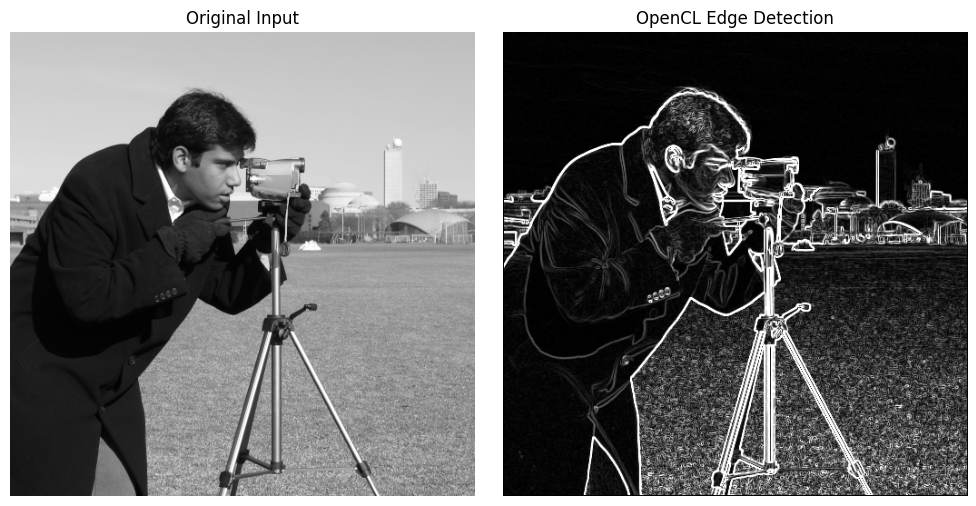

✅ Test Complete. If you see edges on the right, your kernel works!


In [ ]:
#Testing to ensure the correctness of the code

# ==========================================
# PART 1: INSTALLATION (Google Colab Only)
# ==========================================
import os
# Check if running in Colab to install dependencies
try:
    import google.colab
    IN_COLAB = True
    print("Installing PyOpenCL and system drivers...")
    os.system('apt-get install -y -qq ocl-icd-opencl-dev opencl-headers')
    os.system('pip install pyopencl')
except:
    IN_COLAB = False
    print("Not in Colab. Assuming dependencies are installed.")

# ==========================================
# PART 2: IMPORTS & SETUP
# ==========================================
import pyopencl as cl
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.transform import resize

# ==========================================
# PART 3: THE KERNEL CODE
# ==========================================
kernel_code = """
__kernel void sobel_filter(__global unsigned char* input_image,
                           __global unsigned char* output_image,
                           const int width,
                           const int height)
{
    int x = get_global_id(0);
    int y = get_global_id(1);

    // Boundary check
    if (x <= 0 || x >= width - 1 || y <= 0 || y >= height - 1) {
        if (x < width && y < height) {
            output_image[y * width + x] = 0;
        }
        return;
    }

    // Sobel Masks
    int Gx[3][3] = {{-1, 0, 1}, {-2, 0, 2}, {-1, 0, 1}};
    int Gy[3][3] = {{-1, -2, -1}, {0, 0, 0}, {1, 2, 1}};

    float sumX = 0.0;
    float sumY = 0.0;

    // Convolution
    for (int i = -1; i <= 1; i++) {
        for (int j = -1; j <= 1; j++) {
            int current_index = (y + i) * width + (x + j);
            unsigned char pixel_val = input_image[current_index];
            sumX += pixel_val * Gx[i + 1][j + 1];
            sumY += pixel_val * Gy[i + 1][j + 1];
        }
    }

    // Magnitude
    int magnitude = (int)sqrt(sumX * sumX + sumY * sumY);

    // Clamp
    if (magnitude > 255) magnitude = 255;
    if (magnitude < 0) magnitude = 0;

    output_image[y * width + x] = (unsigned char)magnitude;
}
"""

# ==========================================
# PART 4: HOST CODE (Test Run) (DUMMY SAHAJA)
# ==========================================

# Teruntuk Esah
# data.camera() ganti dengan cv2.imread() utk load custom images.
# untuk OpenCL gpu version (THIS CODE) dah buat since nak check correctness dia (UBAH YG AKU MENTION ATAS NI JE data.camera() tu)
# next step kena buat code in cpu version (sequential) utk write slow version dia. sbb nak compare dua ni nanti utk performance analysis
# another next step is untuk benchmarking which is the timing. means kena add timer kat
def run_test():
    # 1. Setup OpenCL Context
    try:
        platform = cl.get_platforms()[0]
        device = platform.get_devices()[0]
        context = cl.Context([device])
        queue = cl.CommandQueue(context)
        print(f"✅ Running on Device: {device.name}")
    except Exception as e:
        print("❌ Error finding OpenCL device. Did you change Runtime to GPU?")
        print(e)
        return

    # 2. Prepare Data (Use a sample image)
    # We use the 'camera' image, resize it to speed up test, and ensure grayscale
    image_rgb = data.camera()
    image_gray = image_rgb.astype(np.uint8) # It's already grayscale

    # Flatten data for the buffer
    host_input = image_gray.flatten()
    host_output = np.zeros_like(host_input)

    height, width = image_gray.shape

    # 3. Create Buffers
    mf = cl.mem_flags
    input_buf = cl.Buffer(context, mf.READ_ONLY | mf.COPY_HOST_PTR, hostbuf=host_input)
    output_buf = cl.Buffer(context, mf.WRITE_ONLY, host_input.nbytes)

    # 4. Compile Program
    program = cl.Program(context, kernel_code).build()

    # 5. Execute Kernel
    # Global work size must be the image dimensions (width, height)
    global_size = (width, height)
    local_size = None # Let PyOpenCL decide

    print(f"🚀 Executing Kernel on {width}x{height} image...")

    program.sobel_filter(queue, global_size, local_size,
                         input_buf, output_buf,
                         np.int32(width), np.int32(height))

    # 6. Read Results
    cl.enqueue_copy(queue, host_output, output_buf)

    # Reshape back to 2D for display
    result_image = host_output.reshape((height, width))

    # ==========================================
    # PART 5: VERIFICATION (Display)
    # ==========================================
    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.title("Original Input")
    plt.imshow(image_gray, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.title("OpenCL Edge Detection")
    plt.imshow(result_image, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
    print("✅ Test Complete. If you see edges on the right, your kernel works!")

# Run the test
run_test()

Image Size: 1024x1024 pixels

[CPU] Starting Sequential Edge Detection...
      (This is intentionally slow to demonstrate the need for GPUs)
✅ [CPU] Done. Time taken: 22.8760 seconds

[GPU] Starting OpenCL Edge Detection...
      Device: Tesla T4


/usr/local/lib/python3.12/dist-packages/pyopencl/__init__.py:570: CompilerWarning: Non-empty compiler output encountered. Set the environment variable PYOPENCL_COMPILER_OUTPUT=1 to see more.
  lambda: self._prg.build(options_bytes, devices),


✅ [GPU] Done. Time taken: 0.0013 seconds

🚀 SPEEDUP REPORT:
Sequential (CPU): 22.8760 s
Parallel   (GPU): 0.0013 s
Speedup Factor  : 17185.87x faster!


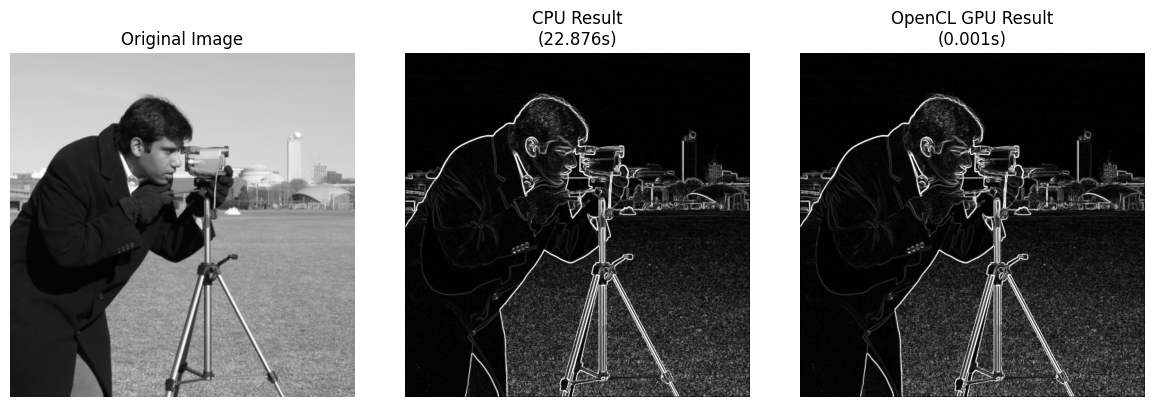

In [ ]:
# =============================================================================
# KT44502 Distributed Systems - Group Assignment (Option B: Image Processing)
# -----------------------------------------------------------------------------
# Combined Implementation:
#   1. OpenCL Kernel (Siti Nurzaihan)
#   2. Host Program & Visualization (Nurul Aniesah)
#   3. Sequential CPU Baseline (Yusuf Naim)
#   4. Main Execution (ALL)
# =============================================================================

import os
import time
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, color
from skimage.transform import resize
import cv2  # OpenCV for image loading

# Check for Colab and install dependencies if missing
try:
    import pyopencl as cl
except ImportError:
    print("Installing PyOpenCL (this may take a moment)...")
    os.system('apt-get install -y -qq ocl-icd-opencl-dev opencl-headers')
    os.system('pip install pyopencl')
    import pyopencl as cl

# =============================================================================
# PART 1: The OpenCL Kernel
# =============================================================================
kernel_code = """
__kernel void sobel_filter(__global unsigned char* input_image,
                           __global unsigned char* output_image,
                           const int width,
                           const int height)
{
    int x = get_global_id(0);
    int y = get_global_id(1);

    // Boundary check: If edge pixel, set to black and exit
    if (x <= 0 || x >= width - 1 || y <= 0 || y >= height - 1) {
        if (x < width && y < height) {
            output_image[y * width + x] = 0;
        }
        return;
    }

    // Sobel Masks (Edge Detection Logic)
    int Gx[3][3] = {{-1, 0, 1}, {-2, 0, 2}, {-1, 0, 1}};
    int Gy[3][3] = {{-1, -2, -1}, {0, 0, 0}, {1, 2, 1}};

    float sumX = 0.0;
    float sumY = 0.0;

    // Convolve 3x3 window
    for (int i = -1; i <= 1; i++) {
        for (int j = -1; j <= 1; j++) {
            int current_index = (y + i) * width + (x + j);
            unsigned char pixel_val = input_image[current_index];
            sumX += pixel_val * Gx[i + 1][j + 1];
            sumY += pixel_val * Gy[i + 1][j + 1];
        }
    }

    // Calculate Magnitude
    int magnitude = (int)sqrt(sumX * sumX + sumY * sumY);

    // Clamp result to 0-255
    if (magnitude > 255) magnitude = 255;
    if (magnitude < 0) magnitude = 0;

    output_image[y * width + x] = (unsigned char)magnitude;
}
"""

# =============================================================================
# PART 2: Sequential CPU Version (Baseline for Comparison)
# =============================================================================
def sobel_cpu_sequential(image):
    print("\n[CPU] Starting Sequential Edge Detection...")
    print("      (This is intentionally slow to demonstrate the need for GPUs)")

    start_time = time.time()

    height, width = image.shape
    output = np.zeros((height, width), dtype=np.int32)

    # Sobel Masks
    Gx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    Gy = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])

    # Nested loops - The slow way!
    for y in range(1, height - 1):
        for x in range(1, width - 1):
            region = image[y-1:y+2, x-1:x+2]
            val_x = np.sum(region * Gx)
            val_y = np.sum(region * Gy)
            magnitude = int(np.sqrt(val_x**2 + val_y**2))
            if magnitude > 255: magnitude = 255
            output[y, x] = magnitude

    end_time = time.time()
    cpu_duration = end_time - start_time
    print(f"✅ [CPU] Done. Time taken: {cpu_duration:.4f} seconds")
    return output.astype(np.uint8), cpu_duration

# =============================================================================
# PART 3: OpenCL Host Code
# =============================================================================
def run_opencl_gpu(image):
    print("\n[GPU] Starting OpenCL Edge Detection...")

    # 1. Setup Platform & Device
    try:
        platform = cl.get_platforms()[0]
        device = platform.get_devices()[0] # Selects the first GPU found
        context = cl.Context([device])
        queue = cl.CommandQueue(context)
        print(f"      Device: {device.name}")
    except Exception as e:
        print("❌ [GPU] Error: No OpenCL device found. Make sure you are using a GPU runtime.")
        return None, 0

    # 2. Prepare Data
    height, width = image.shape
    host_input = image.flatten() # 1D array
    host_output = np.zeros_like(host_input)

    # 3. Memory Allocation (Create Buffers)
    mf = cl.mem_flags
    input_buf = cl.Buffer(context, mf.READ_ONLY | mf.COPY_HOST_PTR, hostbuf=host_input)
    output_buf = cl.Buffer(context, mf.WRITE_ONLY, host_input.nbytes)

    # 4. Compile Kernel
    program = cl.Program(context, kernel_code).build()

    # 5. Execute Kernel
    global_size = (width, height)
    local_size = None # Let the driver decide best work-group size

    start_time = time.time()

    # Enqueue the kernel
    program.sobel_filter(queue, global_size, local_size,
                         input_buf, output_buf,
                         np.int32(width), np.int32(height))

    # Wait for finish (synchronize) to get accurate timing
    queue.finish()

    end_time = time.time()
    gpu_duration = end_time - start_time

    # 6. Retrieve Results
    cl.enqueue_copy(queue, host_output, output_buf)
    result_image = host_output.reshape((height, width))

    print(f"✅ [GPU] Done. Time taken: {gpu_duration:.4f} seconds")
    return result_image, gpu_duration

# =============================================================================
# MAIN EXECUTION
# =============================================================================
if __name__ == "__main__":
    # --- STEP 1: LOAD IMAGE ---
    # OPTION A: Use a built-in sample
    # Note: data.camera() is already grayscale
    raw_image = data.camera()

    # OPTION B: Load own uploaded file (Uncomment below to use)
    # filename = "my_uploaded_image.jpg"
    # if os.path.exists(filename):
    #     raw_image = cv2.imread(filename)
    #     # OpenCV loads as BGR, convert to RGB for consistency
    #     if len(raw_image.shape) == 3:
    #         raw_image = cv2.cvtColor(raw_image, cv2.COLOR_BGR2RGB)

    # Resize to ensure it's large enough (1024x1024)
    image_resized = resize(raw_image, (1024, 1024), anti_aliasing=True)

    # --- FIX: SMART GRAYSCALE CONVERSION ---
    # Check if the image has 3 color channels (RGB) or is already 2D (Grayscale)
    if len(image_resized.shape) == 3 and image_resized.shape[2] == 3:
        # It's RGB, so convert to Gray
        image_gray = (color.rgb2gray(image_resized) * 255).astype(np.uint8)
    else:
        # It's already Grayscale, just scale to 0-255
        image_gray = (image_resized * 255).astype(np.uint8)

    print(f"Image Size: {image_gray.shape[1]}x{image_gray.shape[0]} pixels")

    # --- STEP 2: RUN CPU VERSION ---
    cpu_result, t_cpu = sobel_cpu_sequential(image_gray)

    # --- STEP 3: RUN GPU VERSION ---
    gpu_result, t_gpu = run_opencl_gpu(image_gray)

    # --- STEP 4: COMPARE & REPORT ---
    if t_gpu > 0:
        speedup = t_cpu / t_gpu
        print(f"\n🚀 SPEEDUP REPORT:")
        print(f"Sequential (CPU): {t_cpu:.4f} s")
        print(f"Parallel   (GPU): {t_gpu:.4f} s")
        print(f"Speedup Factor  : {speedup:.2f}x faster!")

    # --- STEP 5: VISUALIZE ---
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(image_gray, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title(f"CPU Result\n({t_cpu:.3f}s)")
    plt.imshow(cpu_result, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title(f"OpenCL GPU Result\n({t_gpu:.3f}s)")
    plt.imshow(gpu_result, cmap='gray')
    plt.axis('off')

    plt.tight_layout()
    plt.show()